**Import**

In [ ]:
#file
#JALANIN INI KETIKA BELUM UPLOAD FILE, SELEBIHNYA EKSEKUSI KODE DIBAWAH AJA
from google.colab import files
uploaded = files.upload()

#Metode Google Drive (Mount)
# from google.colab import drive
# drive.mount('/content/drive')
# file_path = '/content/drive/MyDrive/ai_worker_burnout_attrition_2026.csv' --> JANGAN DI TARO DI FOLDER, LANGSUNG DI DRIVE, NAMA SESUAIIN

Saving ai_worker_burnout_attrition_2026.csv to ai_worker_burnout_attrition_2026.csv


In [ ]:
# Other Imports

# core lib
import pandas as pd #hidup panda!!!
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# lib sklearn
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
# sklearn model selection
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score, median_absolute_error, explained_variance_score)

# models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import xgboost as xgb

# visual
import warnings
warnings.filterwarnings('ignore') # ignore
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6) # 12 x 6

**Load** **dataset**

In [ ]:
# load
df = pd.read_csv('ai_worker_burnout_attrition_2026.csv')
# df = pd.read_csv(file_path) --> kalau pakai mount

print(f"Loaded\n{df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

Loaded
1,500 rows, 21 columns


,employee_id,job_role,years_experience,education_level,country,industry,company_size,remote_work_type,team_size,salary_usd_k,...,ai_tools_used_per_day,hours_with_ai_assistance_daily,ai_replaces_my_tasks_pct,ai_adoption_stage,weekly_ai_upskilling_hrs,productivity_score,burnout_score,job_satisfaction_1_5,fear_of_ai_replacement,attrition_risk
0,EMP0001,Data Analyst,7,PhD,India,Healthtech,Large (1000-5000),Fully Remote,8,184,...,1,0.6,37,Experimenting,4.9,59,58,3.0,Low,Medium
1,EMP0002,DevOps Engineer,3,Self-taught,Canada,Fintech,Large (1000-5000),Hybrid,42,51,...,3,0.6,78,Experimenting,6.6,64,47,3.6,Medium,Medium
2,EMP0003,Prompt Engineer,3,PhD,India,Automotive,Startup (<50),Hybrid,37,185,...,4,4.0,23,Optimizing,5.8,50,37,4.6,High,Medium
3,EMP0004,Backend Engineer,18,Master,Germany,Media,Mid (200-1000),Fully Remote,8,131,...,5,4.2,75,Integrating,1.4,77,67,3.0,Low,Medium
4,EMP0005,AI Researcher,5,Bachelor,India,E-commerce,Small (50-200),Fully Remote,21,99,...,7,0.7,61,Experimenting,1.6,58,54,3.6,Medium,Medium


**Exploration**


Memory usage: 1.02 MB

Column:
['employee_id', 'job_role', 'years_experience', 'education_level', 'country', 'industry', 'company_size', 'remote_work_type', 'team_size', 'salary_usd_k', 'primary_ai_tool', 'ai_tools_used_per_day', 'hours_with_ai_assistance_daily', 'ai_replaces_my_tasks_pct', 'ai_adoption_stage', 'weekly_ai_upskilling_hrs', 'productivity_score', 'burnout_score', 'job_satisfaction_1_5', 'fear_of_ai_replacement', 'attrition_risk']
employee_id                        object
job_role                           object
years_experience                    int64
education_level                    object
country                            object
industry                           object
company_size                       object
remote_work_type                   object
team_size                           int64
salary_usd_k                        int64
primary_ai_tool                    object
ai_tools_used_per_day               int64
hours_with_ai_assistance_daily    float64
ai_re

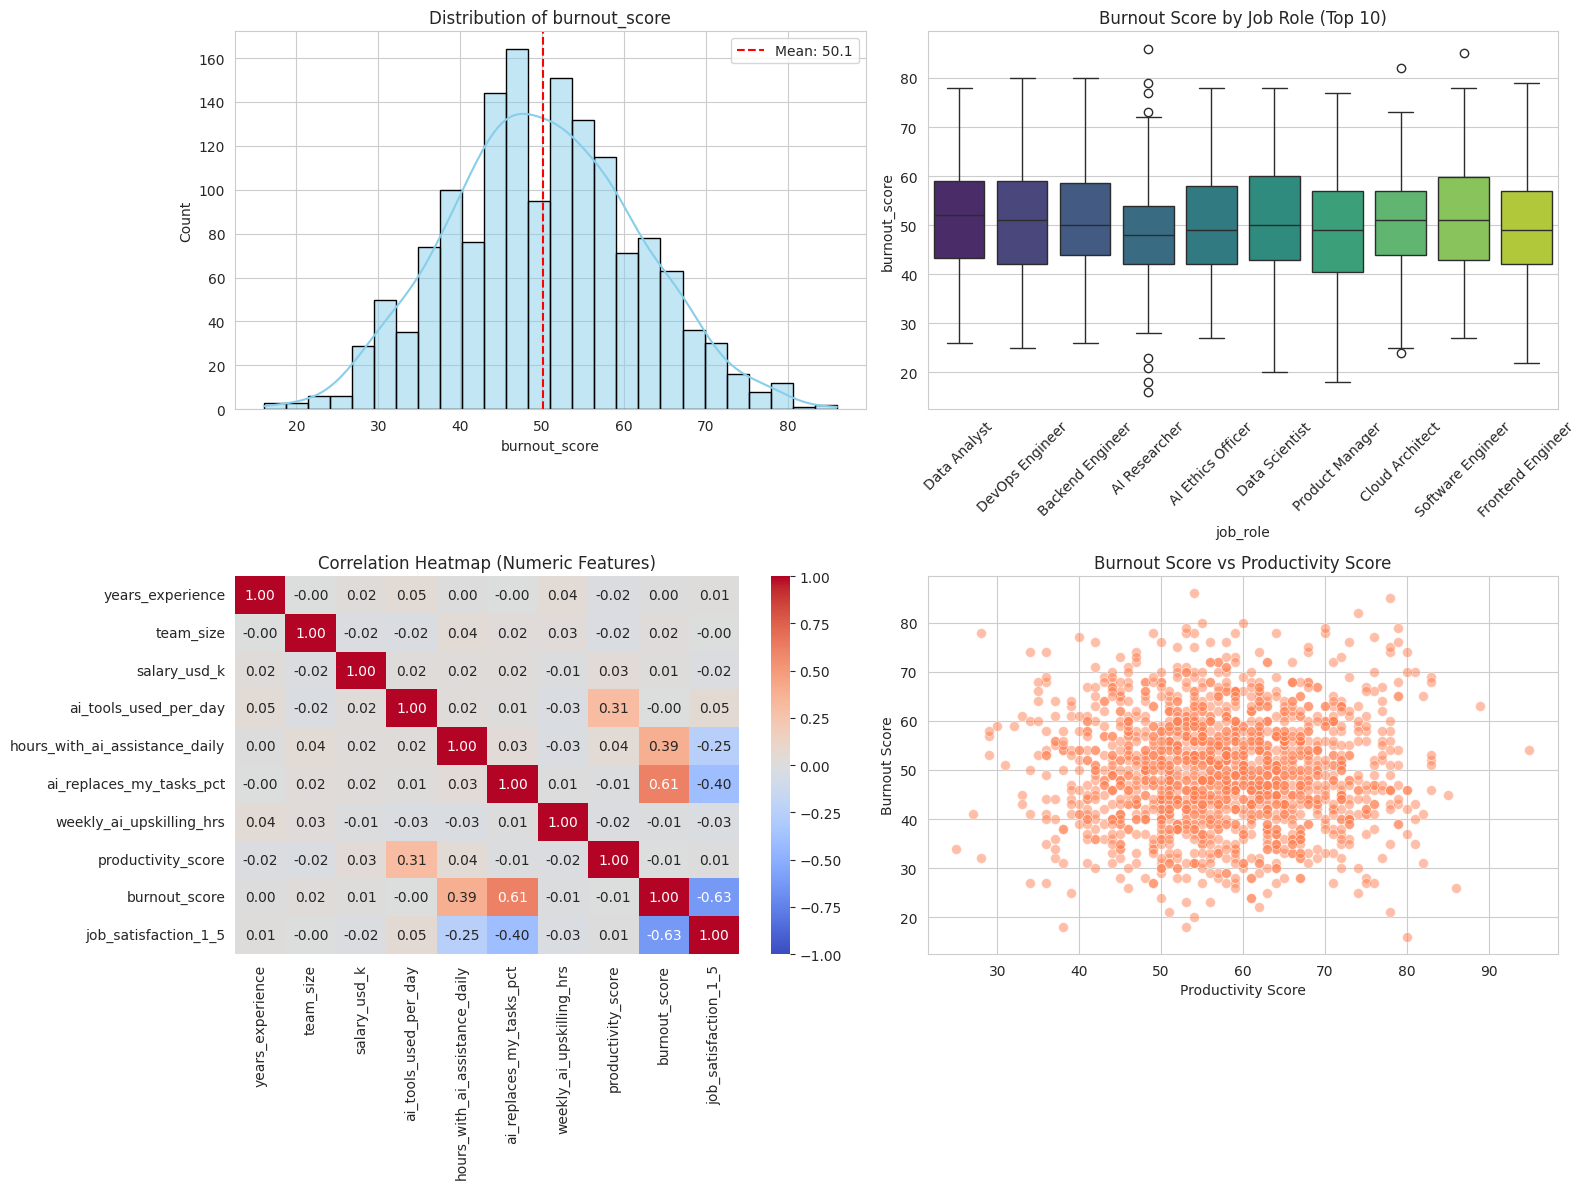

In [ ]:
# explore
print(f"\nMemory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(f"\nColumn:\n{df.columns.tolist()}")

print(df.dtypes)
print(f"\nMissing values (Column): {df.isnull().sum()}")
print(f"\nTotal missing: {df.isnull().sum().sum():,} ({df.isnull().sum().sum()/len(df)*100:.2f}%)")

# visualisasi explore
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
target_col = 'burnout_score'

# chart 1 - distribusi burnout
sns.histplot(df[target_col], ax=axes[0,0], kde=True, color='skyblue', edgecolor='black')
axes[0,0].axvline(df[target_col].mean(), color='red', linestyle='--', label=f"Mean: {df[target_col].mean():.1f}")
axes[0,0].set_title(f'Distribution of {target_col}')
axes[0,0].legend()

# chart 2 - top 10 role
top_roles = df['job_role'].value_counts().head(10).index
df_top = df[df['job_role'].isin(top_roles)]
sns.boxplot(data=df_top, x='job_role', y=target_col, ax=axes[0,1], palette='viridis')
axes[0,1].set_title('Burnout Score by Job Role (Top 10)')
axes[0,1].tick_params(axis='x', rotation=45)

# chart 3 - heatmap
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1,0],
            vmin=-1, vmax=1, center=0)
axes[1,0].set_title('Correlation Heatmap (Numeric Features)')

# chart 4 - burnout dan productivity
sns.scatterplot(data=df, x='productivity_score', y=target_col,
                alpha=0.5, s=50, ax=axes[1,1], color='coral')
axes[1,1].set_title('Burnout Score vs Productivity Score')
axes[1,1].set_xlabel('Productivity Score')
axes[1,1].set_ylabel('Burnout Score')

plt.tight_layout()
plt.show()

Data Cleaning - Check Missing value

In [ ]:
print("Column di dalam CSV")
print(df.columns.tolist())
print("\nCek column mana yang bolong:")
print(df.isna().sum())
print("\nCek berapa banyak column dan baris: (column, baris)")
print(df.shape)

print("\nCek apakah ada empty string")
print(df.select_dtypes(include='object').apply(lambda x: (x == "").sum()))

print("\nTotal semua yang tidak null")
print(df.count())

Column di dalam CSV
['employee_id', 'job_role', 'years_experience', 'education_level', 'country', 'industry', 'company_size', 'remote_work_type', 'team_size', 'salary_usd_k', 'primary_ai_tool', 'ai_tools_used_per_day', 'hours_with_ai_assistance_daily', 'ai_replaces_my_tasks_pct', 'ai_adoption_stage', 'weekly_ai_upskilling_hrs', 'productivity_score', 'burnout_score', 'job_satisfaction_1_5', 'fear_of_ai_replacement', 'attrition_risk']

Cek column mana yang bolong:
employee_id                       0
job_role                          0
years_experience                  0
education_level                   0
country                           0
industry                          0
company_size                      0
remote_work_type                  0
team_size                         0
salary_usd_k                      0
primary_ai_tool                   0
ai_tools_used_per_day             0
hours_with_ai_assistance_daily    0
ai_replaces_my_tasks_pct          0
ai_adoption_stage            

Data Cleaning - Duplicate Check

In [ ]:
print("Data yang duplikat:")
print(df.duplicated().sum())

# apabila ada row yang duplikat bakal di drop
df = df.drop_duplicates()

# Jaga jaga cek employee_id ada duplikat atau nggak
print("Employee ID yang duplikat:")
print(df['employee_id'].duplicated().sum())

# drop row dengan id yang duplikat
df = df.drop_duplicates(subset='employee_id')

Data yang duplikat:
0
Employee ID yang duplikat:
0


Data cleaning - Typo/Value Consistency Check

In [ ]:
for col in df.select_dtypes(include='object'):
    print("Column:", col)
    print(df[col].value_counts())
    print("-------------")

# kalau ada hidden space atau spasi kelebihan jaga-jaga
for col in df.select_dtypes(include='object'):
    df[col] = df[col].str.strip()

Column: employee_id
employee_id
EMP1500    1
EMP0001    1
EMP0002    1
EMP0003    1
EMP0004    1
          ..
EMP0017    1
EMP0016    1
EMP0015    1
EMP0014    1
EMP0013    1
Name: count, Length: 1500, dtype: int64
-------------
Column: job_role
job_role
Software Engineer    150
AI Researcher        135
Data Scientist       135
AI Ethics Officer    132
Cloud Architect      130
Backend Engineer     127
Product Manager      123
Data Analyst         122
Frontend Engineer    116
DevOps Engineer      116
ML Engineer          109
Prompt Engineer      105
Name: count, dtype: int64
-------------
Column: education_level
education_level
Master         323
Bachelor       314
PhD            294
Self-taught    285
Bootcamp       284
Name: count, dtype: int64
-------------
Column: country
country
France         178
UK             169
Netherlands    161
Canada         151
USA            150
Germany        150
Australia      147
Brazil         135
India          131
Singapore      128
Name: count, dty

Data Cleaning - Numerical Check and Outlier Check

In [ ]:
print("Numerik detail smeua kolumn")
print(df.describe())
numerical_cols = df.select_dtypes(include=['int64','float64']).columns

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    print(col)
    print("Lower bound:", lower)
    print("Upper bound:", upper)
    print("Outliers:", df[(df[col] < lower) | (df[col] > upper)].shape[0])
    print("----------------")

rows_before = df.shape[0]

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

rows_after = df.shape[0]

print("Rows before:", rows_before)
print("Rows after:", rows_after)
print("Removed:", rows_before - rows_after)

Numerik detail smeua kolumn
       years_experience    team_size  salary_usd_k  ai_tools_used_per_day  \
count       1500.000000  1500.000000   1500.000000             1500.00000   
mean           9.947333    24.812667    140.734000                4.05600   
std            5.460932    13.682582     59.717429                1.97403   
min            1.000000     2.000000     40.000000                1.00000   
25%            5.000000    13.000000     91.000000                2.00000   
50%           10.000000    25.000000    139.000000                4.00000   
75%           15.000000    36.000000    190.000000                6.00000   
max           19.000000    49.000000    249.000000                7.00000   

       hours_with_ai_assistance_daily  ai_replaces_my_tasks_pct  \
count                     1500.000000               1500.000000   
mean                         4.233733                 41.248667   
std                          2.148387                 21.658214   
min       

**Splitting**


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_final,
    y_final,
    test_size=0.2, # test 20%
    random_state=42,
    shuffle=True # shuffle
)

print(f"Training set: {X_train.shape[0]:,} samples ({X_train.shape[0]/len(X_final)*100:.1f}%)")
print(f"Testing set:  {X_test.shape[0]:,} samples ({X_test.shape[0]/len(X_final)*100:.1f}%)")
print(f"Target distribution (Train): mean = {y_train.mean():.2f}, std = {y_train.std():.2f}")
print(f"Target distribution (Test):  mean = {y_test.mean():.2f}, std = {y_test.std():.2f}")

Training set: 1,192 samples (79.9%)
Testing set:  299 samples (20.1%)
Target distribution (Train): mean = 50.05, std = 11.30
Target distribution (Test):  mean = 49.82, std = 11.38


**Final Preprocessing**

In [ ]:
target_col = 'burnout_score'
drop_cols = ['employee_id', target_col]
feature_cols = [col for col in df.columns if col not in drop_cols]

X = df[feature_cols].copy()
y = df[target_col].copy()

# cleaning null
y = pd.to_numeric(y, errors='coerce')
mask = ~y.isna() # kalau ada null
X = X[mask]
y = y[mask]

print(f"Cleaning result: {len(X):,}")

# identifikasi tipe
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

# label
label_encoders = {}
for col in categorical_features:
  le = LabelEncoder()
  X[col] = le.fit_transform(X[col].astype(str))
  label_encoders[col] = le

# save hasil
for col, le in label_encoders.items():
  print(f"   {col}: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
print("Data scaled\n")

# finalisasi
X_final = X_scaled
y_final = y
print("Preprocessing done")

Cleaning result: 1,491
   job_role: {'AI Ethics Officer': np.int64(0), 'AI Researcher': np.int64(1), 'Backend Engineer': np.int64(2), 'Cloud Architect': np.int64(3), 'Data Analyst': np.int64(4), 'Data Scientist': np.int64(5), 'DevOps Engineer': np.int64(6), 'Frontend Engineer': np.int64(7), 'ML Engineer': np.int64(8), 'Product Manager': np.int64(9), 'Prompt Engineer': np.int64(10), 'Software Engineer': np.int64(11)}
   education_level: {'Bachelor': np.int64(0), 'Bootcamp': np.int64(1), 'Master': np.int64(2), 'PhD': np.int64(3), 'Self-taught': np.int64(4)}
   country: {'Australia': np.int64(0), 'Brazil': np.int64(1), 'Canada': np.int64(2), 'France': np.int64(3), 'Germany': np.int64(4), 'India': np.int64(5), 'Netherlands': np.int64(6), 'Singapore': np.int64(7), 'UK': np.int64(8), 'USA': np.int64(9)}
   industry: {'Automotive': np.int64(0), 'Consulting': np.int64(1), 'Cybersecurity': np.int64(2), 'E-commerce': np.int64(3), 'EdTech': np.int64(4), 'Fintech': np.int64(5), 'Gaming': np.int64(

**Models and Training/Testing**

In [ ]:
# models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5, # min_split / 2
        random_state=42
    ),
    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_split=10,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    )
}

results = {}

# train dan test
for name, model in models.items():
  print(f"Model: {name}")

  model.fit(X_train, y_train)
  y_train_pred = model.predict(X_train)
  y_test_pred = model.predict(X_test)

  train_mae = mean_absolute_error(y_train, y_train_pred)
  train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
  train_r2 = r2_score(y_train, y_train_pred)

  test_mae = mean_absolute_error(y_test, y_test_pred)
  test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
  test_r2 = r2_score(y_test, y_test_pred)

  results[name] = {
      'model': model,
      'train_mae': train_mae,
      'train_rmse': train_rmse,
      'train_r2': train_r2,
      'test_mae': test_mae,
      'test_rmse': test_rmse,
      'test_r2': test_r2,
      'y_test_pred': y_test_pred
  }

  print(f"TRAINING\n")
  print(f"Train MAE: {train_mae:.2f}\n")
  print(f"Train RMSE: {train_rmse:.2f}\n")
  print(f"Train R2: {train_r2:.2f}\n")

  print(f"TESTING\n")
  print(f"Test MAE: {test_mae:.2f}\n")
  print(f"Test RMSE: {test_rmse:.2f}\n")
  print(f"Test R2: {test_r2:.2f}")

  if test_r2 >= 0.8:
    print("Excellent fit")
  elif test_r2 >= 0.8:
    print("Good fit")
  elif test_r2 >= 0.6:
    print("Fair fit")
  else:
    print("Poor fit")

comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Test MAE': [results[m]['test_mae'] for m in results.keys()],
    'Test RMSE': [results[m]['test_rmse'] for m in results.keys()],
    'Test R2': [results[m]['test_r2'] for m in results.keys()]
}).sort_values('Test R2', ascending=False)
print(comparison_df.to_string(index=False))



Model: Linear Regression
TRAINING

Train MAE: 5.51

Train RMSE: 6.92

Train R2: 0.62

TESTING

Test MAE: 5.50

Test RMSE: 6.91

Test R2: 0.63
Fair fit
Model: Decision Tree
TRAINING

Train MAE: 3.51

Train RMSE: 4.49

Train R2: 0.84

TESTING

Test MAE: 7.17

Test RMSE: 9.06

Test R2: 0.36
Poor fit
Model: Random Forest
TRAINING

Train MAE: 3.57

Train RMSE: 4.58

Train R2: 0.84

TESTING

Test MAE: 5.67

Test RMSE: 7.15

Test R2: 0.60
Fair fit
            Model  Test MAE  Test RMSE  Test R2
Linear Regression  5.499001   6.913525 0.629462
    Random Forest  5.670276   7.151726 0.603488
    Decision Tree  7.173970   9.062955 0.363243


**Cross Validation**

In [ ]:
ep_results = {}

for name, model in models.items():
  print(f"Model: {name}")

  ep_mae = -cross_val_score(
      model,
      X_final,
      y_final,
      cv=5,
      scoring='neg_mean_absolute_error'
  )
  ep_rmse = np.sqrt(-cross_val_score(
      model,
      X_final,
      y_final,
      cv=5,
      scoring='neg_mean_squared_error'
  ))
  ep_r2 = cross_val_score(
      model,
      X_final,
      y_final,
      cv=5,
      scoring='r2'
  )

  ep_results[name] = {
      'mae_mean': ep_mae.mean(),
      'mae_std': ep_mae.std(),
      'rmse_mean': ep_rmse.mean(),
      'rmse_std': ep_rmse.std(),
      'r2_mean': ep_r2.mean(),
      'r2_std': ep_r2.std()
  }

  print(f"MAE: {ep_mae.mean():.2f} +/- {ep_mae.std():.2f}")
  print(f"RMSE: {ep_rmse.mean():.2f} +/- {ep_rmse.std():.2f}")
  print(f"R2: {ep_r2.mean():.2f} +/- {ep_r2.std():.2f}")

# compare
print(f"Compare:\n")
ep_df = pd.DataFrame({
    'Model': list(ep_results.keys()),
    '(CV) MAE': [ep_results[m]['mae_mean'] for m in ep_results.keys()],
    '(CV) MAE Std': [ep_results[m]['mae_std'] for m in ep_results.keys()],
    '(CV) R2': [ep_results[m]['r2_mean'] for m in ep_results.keys()],
    '(CV) R2 Std': [ep_results[m]['r2_std'] for m in ep_results.keys()]
}).sort_values('(CV) R2', ascending=False)
print(ep_df.to_string(index=False))

Model: Linear Regression
MAE: 5.58 +/- 0.14
RMSE: 7.01 +/- 0.16
R2: 0.62 +/- 0.02
Model: Decision Tree
MAE: 6.97 +/- 0.18
RMSE: 8.68 +/- 0.25
R2: 0.41 +/- 0.02
Model: Random Forest
MAE: 5.74 +/- 0.14
RMSE: 7.21 +/- 0.17
R2: 0.59 +/- 0.02
Compare:

            Model  (CV) MAE  (CV) MAE Std  (CV) R2  (CV) R2 Std
Linear Regression  5.580991      0.142340 0.615072     0.015233
    Random Forest  5.736681      0.138380 0.591622     0.020420
    Decision Tree  6.970683      0.180848 0.409912     0.017346


**Prediction Accuracy Visualization**

Red: actual result
Blue: prediction result


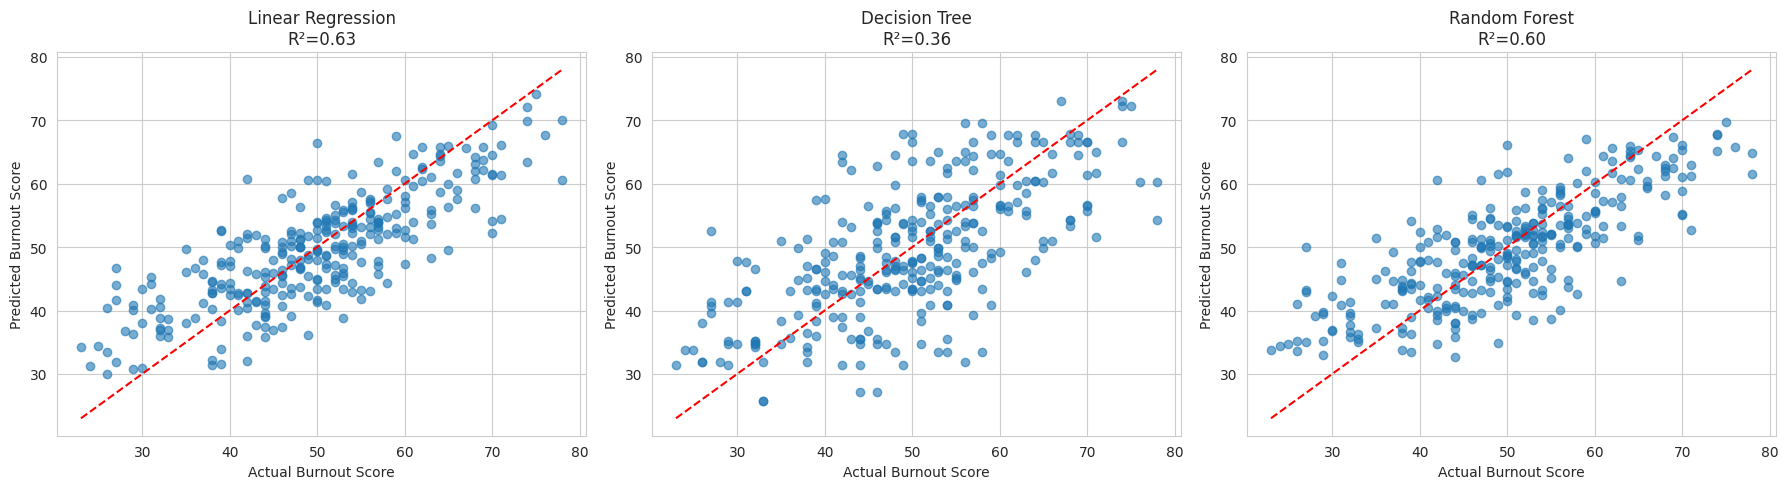

In [ ]:
#  visual scatter plot untuk akurasi prediksi setiap model yg dipakai
n_models = len(results)

fig, axes = plt.subplots(1, n_models, figsize=(6*n_models,5))

if n_models == 1:
    axes = [axes]

for ax, (name, res) in zip(axes, results.items()):
    y_pred = res['y_test_pred']
    ax.scatter(y_test, y_pred, alpha=0.6)
    ax.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        'r--'
    )
    ax.set_title(f"{name}\nR²={res['test_r2']:.2f}")
    ax.set_xlabel("Actual Burnout Score")
    ax.set_ylabel("Predicted Burnout Score")

#  semakin merapat ke red diagonal = semakin akurat
print("Red: actual result\nBlue: prediction result")
plt.tight_layout()
plt.show()


**Residual Plot & Histogram**

Residual Scatter Plot


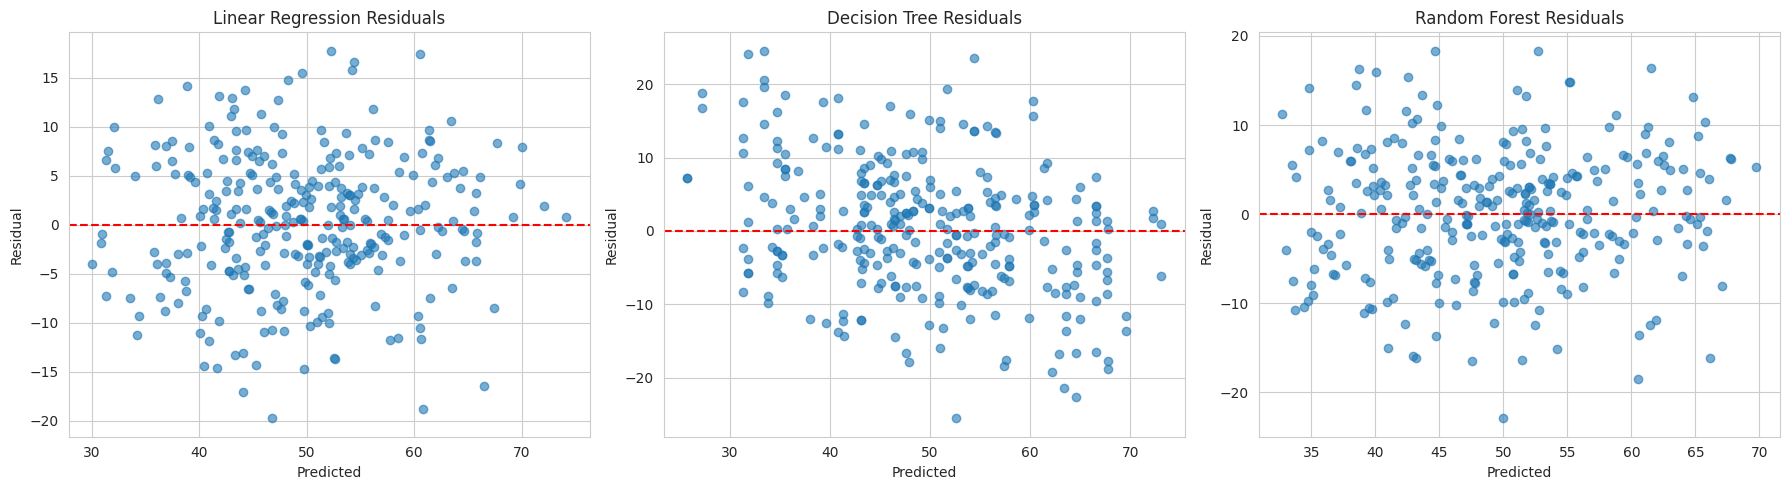

Residual Histogram


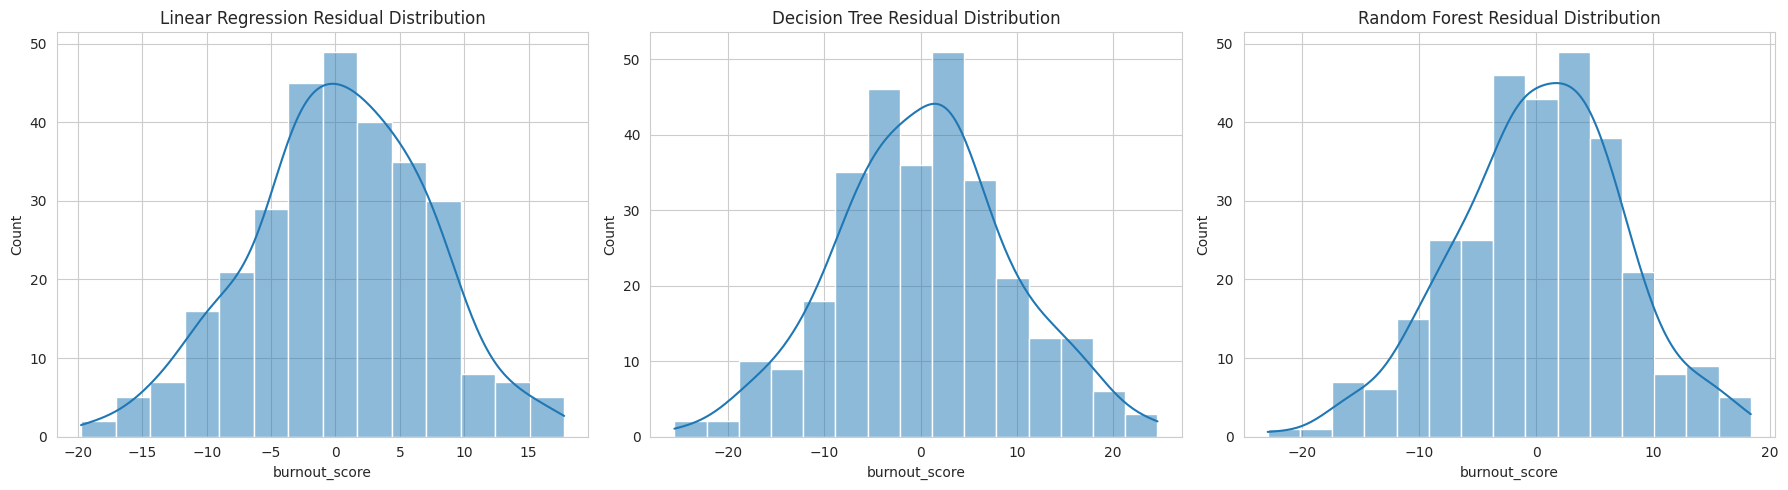

In [ ]:
#  untuk cek apakah model udah hubungin relation pattern dalam dataset
#  scatter plot residual, kalau non-pattern/random = model cocok, kalau ada pola = underfitting
fig, axes = plt.subplots(1, n_models, figsize=(6*n_models,5))

if n_models == 1:
    axes = [axes]

for ax, (name, res) in zip(axes, results.items()):
    y_pred = res['y_test_pred']
    residuals = y_test - y_pred
    ax.scatter(y_pred, residuals, alpha=0.6)
    ax.axhline(0, linestyle='--', color='red')
    ax.set_title(f"{name} Residuals")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Residual")

print("Residual Scatter Plot")
plt.tight_layout()
plt.show()

#  histogram residual, untuk cek error distribution & bias (kalau ada)
fig, axes = plt.subplots(1, n_models, figsize=(6*n_models,5))

if n_models == 1:
    axes = [axes]

for ax, (name, res) in zip(axes, results.items()):
    y_pred = res['y_test_pred']
    residuals = y_test - y_pred
    sns.histplot(residuals, kde=True, ax=ax)
    ax.set_title(f"{name} Residual Distribution")

print("Residual Histogram")
plt.tight_layout()
plt.show()

**Feature** **Importance**

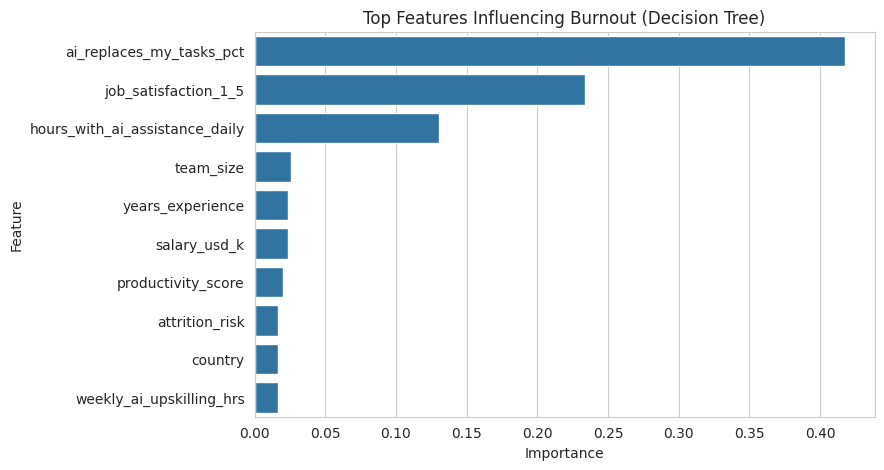

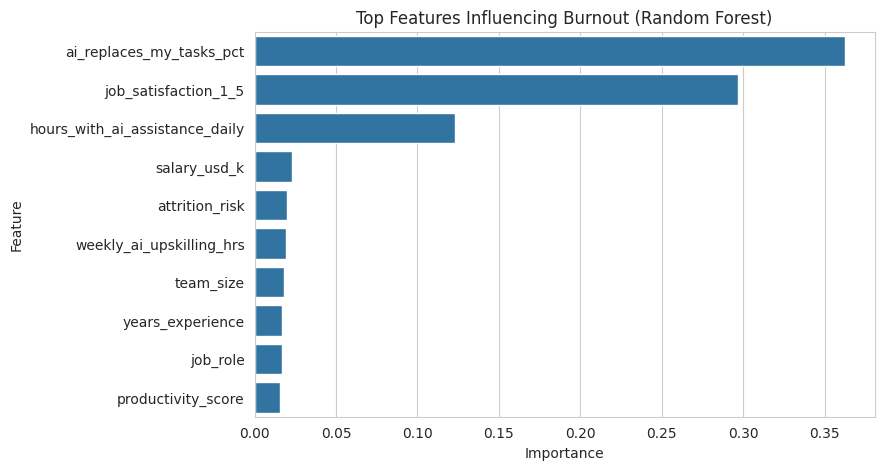

In [ ]:
#  grafik untk tunjukin column/fitur mana yang paling berpengaruh
#  terhadap y = burnout_score (cuma untuk tree-based models)
tree_models = ['Decision Tree', 'Random Forest']

for name in tree_models:

    model = results[name]['model']

    importances = model.feature_importances_

    feat_imp = pd.Series(importances, index=X_train.columns)
    feat_imp = feat_imp.sort_values(ascending=False).head(10)

    plt.figure(figsize=(8,5))

    sns.barplot(x=feat_imp.values, y=feat_imp.index)

    plt.title(f"Top Features Influencing Burnout ({name})")
    plt.xlabel("Importance")
    plt.ylabel("Feature")

    plt.show()


**Performance Summary**

,Model,Train R2,Test R2,Test MAE,Test RMSE
0,Linear Regression,0.624838,0.629462,5.499001,6.913525
2,Random Forest,0.835338,0.603488,5.670276,7.151726
1,Decision Tree,0.841925,0.363243,7.173970,9.062955


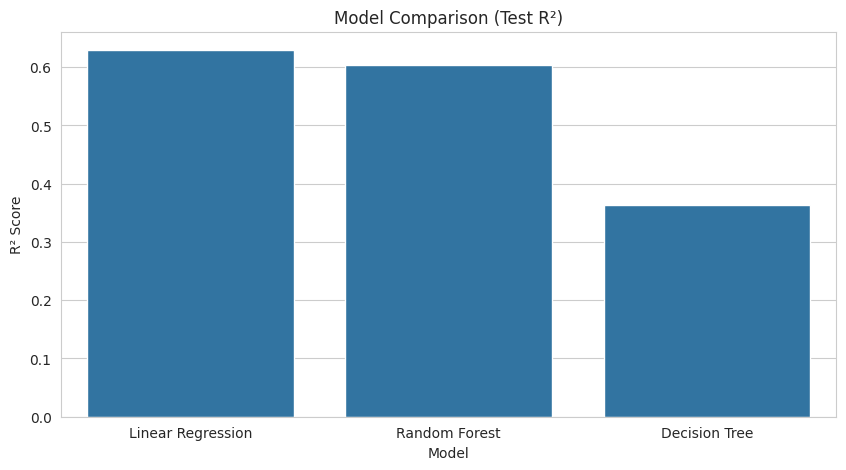

In [ ]:
#  model performance summary dgn data table & simple graph
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Train R2': [results[m]['train_r2'] for m in results],
    'Test R2': [results[m]['test_r2'] for m in results],
    'Test MAE': [results[m]['test_mae'] for m in results],
    'Test RMSE': [results[m]['test_rmse'] for m in results]
}).sort_values('Test R2', ascending=False)

display(comparison_df)

plt.figure(figsize=(10,5))
sns.barplot(data=comparison_df, x='Model', y='Test R2')
plt.title("Model Comparison (Test R²)")
plt.ylabel("R² Score")
plt.xlabel("Model")
plt.show()
